# Part I - Simulating Uniform Convergence

### Task 1 - Empirical Risk as a Random Variable

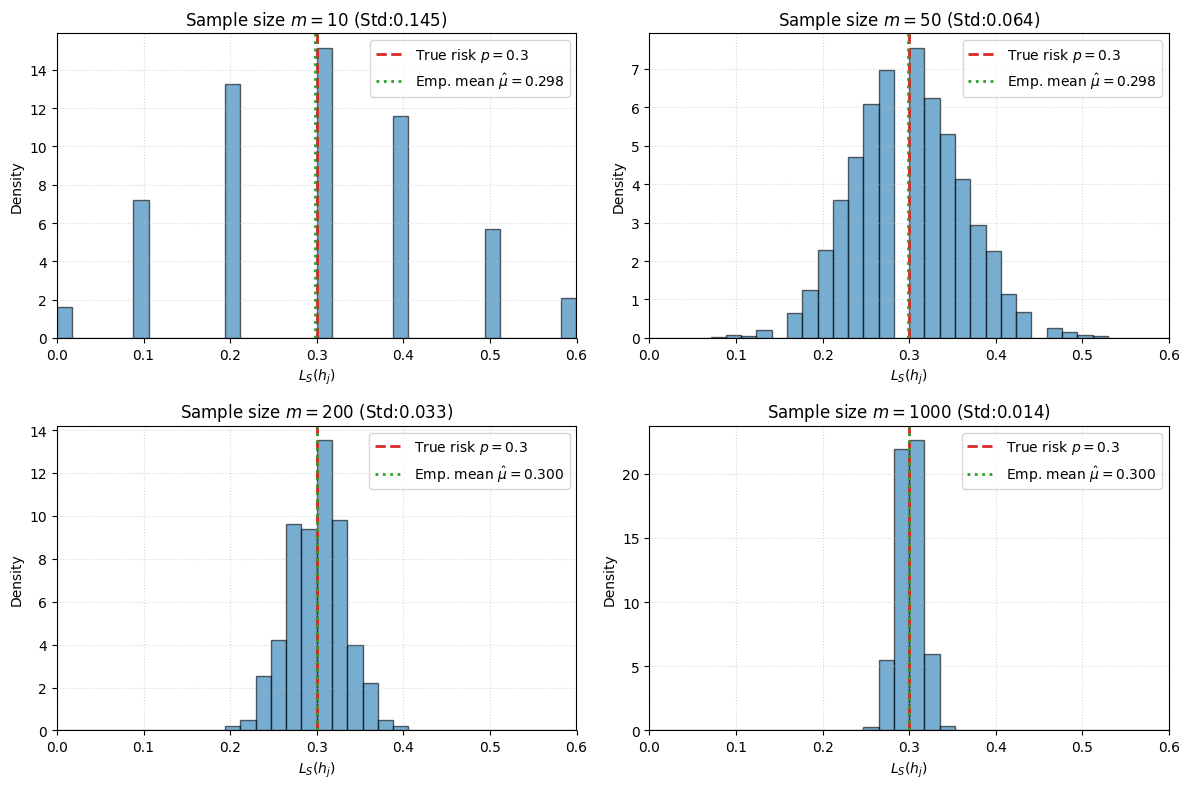

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

p_true=0.3
sample_sizes_task1=[10,50,200,1000]
n_simulations=5000

fig,axes=plt.subplots(2,2,figsize=(12,8))
axes=axes.flatten()

for idx,m in enumerate(sample_sizes_task1):
  errors=np.random.binomial(m,p_true,size=n_simulations)
  empirical_risks=errors/m
  mean_emp=np.mean(empirical_risks)
  std_emp=np.std(empirical_risks)
  ax=axes[idx]
  ax.hist(empirical_risks,bins=np.linspace(0,0.6,35),density=True,alpha=0.6,color='tab:blue',edgecolor='black')
  ax.axvline(p_true,color='tab:red',linestyle='--',linewidth=2,label=f'True risk $p={p_true}$')
  ax.axvline(mean_emp,color='tab:green',linestyle=':',linewidth=2,label=f'Emp. mean $\\hat{{\\mu}}={mean_emp:.3f}$')
  ax.set_title(f'Sample size $m={m}$ (Std:{std_emp:.3f})')
  ax.set_xlabel('$L_S(h_j)$')
  ax.set_ylabel('Density')
  ax.set_xlim(0.0,0.6)
  ax.legend(loc='upper right')
  ax.grid(True,linestyle=':',alpha=0.5)

plt.tight_layout()
plt.show()

### Task 2 - Deviation Between Empirical and True Risk

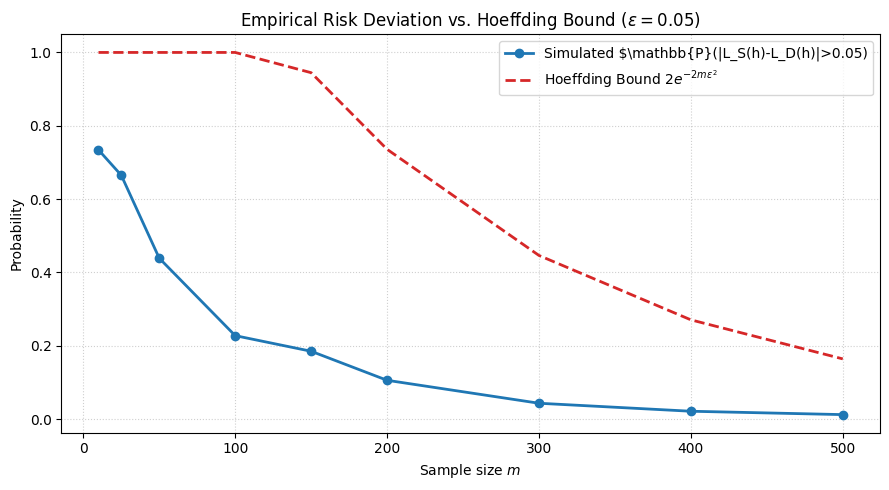

In [ ]:
epsilon=0.05
sample_sizes_task2=np.array([10,25,50,100,150,200,300,400,500])
p_val=0.3

empirical_probs=[]

for m in sample_sizes_task2:
  errors=np.random.binomial(m,p_val,size=n_simulations)
  emp_risks=errors/m
  deviations=np.abs(emp_risks-p_val)
  prob=np.mean(deviations>epsilon)
  empirical_probs.append(prob)

hoeffding_bound=2.0*np.exp(-2.0*sample_sizes_task2*(epsilon**2))
hoeffding_bound=np.minimum(1.0,hoeffding_bound)

plt.figure(figsize=(9,5))
plt.plot(sample_sizes_task2,empirical_probs,marker='o',color='tab:blue',linewidth=2,label=f'Simulated $\\mathbb{{P}}(|L_S(h)-L_D(h)|>{epsilon})$')
plt.plot(sample_sizes_task2,hoeffding_bound,linestyle='--',color='tab:red',linewidth=2,label='Hoeffding Bound $2e^{-2m\\epsilon^2}$')

plt.title(f'Empirical Risk Deviation vs. Hoeffding Bound ($\\epsilon={epsilon}$)')
plt.xlabel('Sample size $m$')
plt.ylabel('Probability')
plt.grid(True,linestyle=':',alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

### Task 3 - The Union Bound and Finite Hypothesis Classes

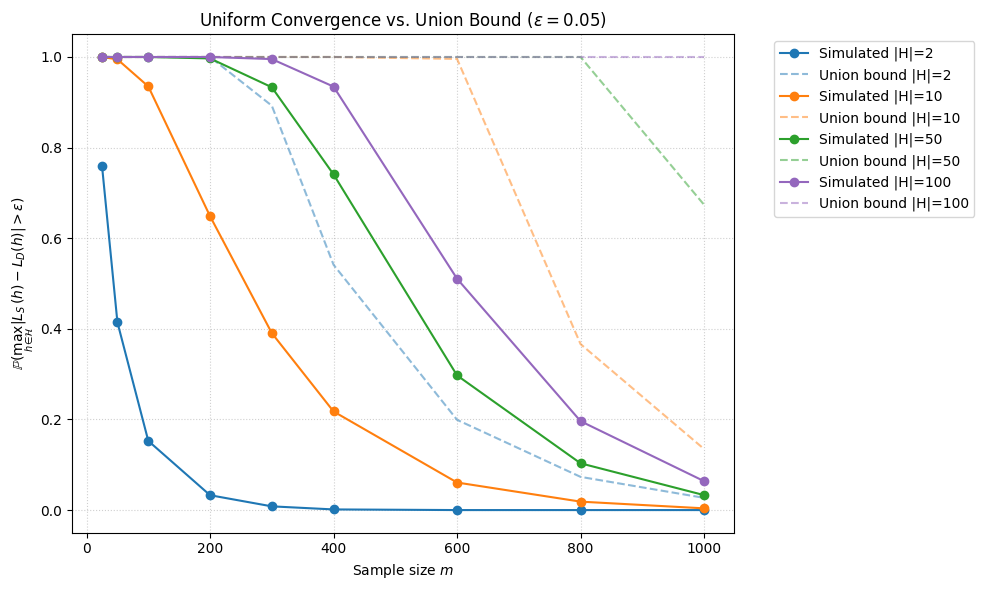

In [ ]:
H_sizes=[2,10,50,100]
sample_sizes_task3=np.array([25,50,100,200,300,400,600,800,1000])

plt.figure(figsize=(10,6))

colors=['tab:blue','tab:orange','tab:green','tab:purple']

for idx,k in enumerate(H_sizes):
  p_vec=np.linspace(0.1,0.9,k)
  simulated_probs=[]
  for m in sample_sizes_task3:
    errors_matrix=np.random.binomial(m,p_vec,size=(n_simulations,k))
    emp_risks_matrix=errors_matrix/m
    max_devs=np.max(np.abs(emp_risks_matrix-p_vec),axis=1)
    prob_fail=np.mean(max_devs>epsilon)
    simulated_probs.append(prob_fail)
  union_bound=np.minimum(1.0,2.0*k*np.exp(-2.0*sample_sizes_task3*(epsilon**2)))
  plt.plot(sample_sizes_task3,simulated_probs,marker='o',color=colors[idx],label=f'Simulated |H|={k}')
  plt.plot(sample_sizes_task3,union_bound,linestyle='--',color=colors[idx],alpha=0.5,label=f'Union bound |H|={k}')

plt.title(f'Uniform Convergence vs. Union Bound ($\\epsilon={epsilon}$)')
plt.xlabel('Sample size $m$')
plt.ylabel('$\\mathbb{P}(\\max_{h\\in\\mathcal{H}}|L_S(h)-L_D(h)|>\\epsilon)$')
plt.grid(True,linestyle=':',alpha=0.6)
plt.legend(bbox_to_anchor=(1.05,1),loc='upper left')
plt.tight_layout()
plt.show()

### Task 4 - Dependence on the Size of the Hypothesis Class

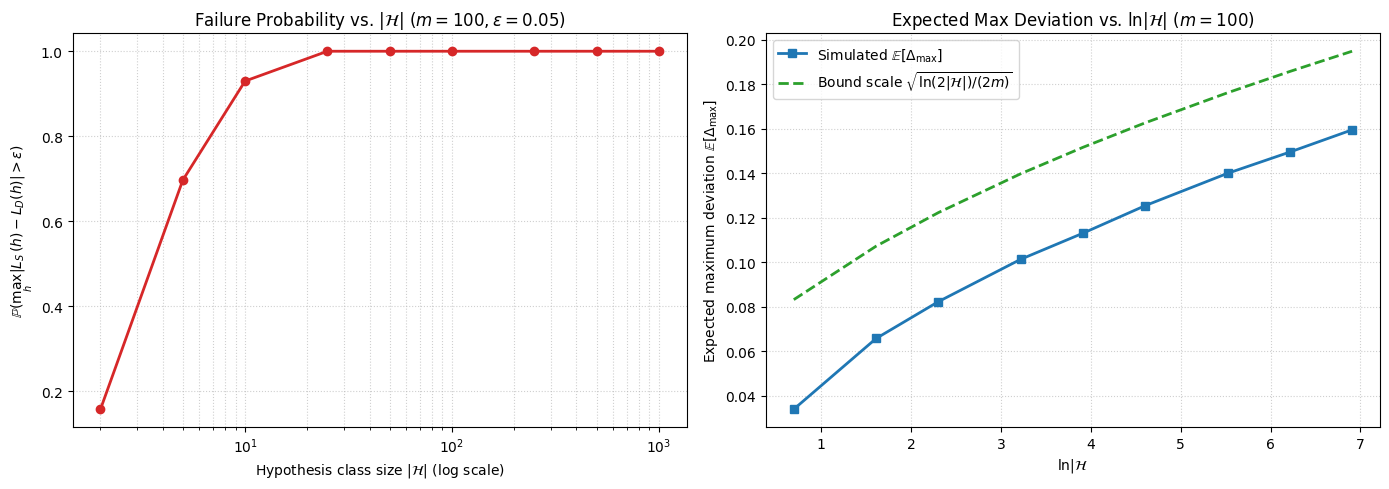

In [ ]:
m_fixed=100
H_range=np.array([2,5,10,25,50,100,250,500,1000])

mean_max_deviations=[]
prob_fail_k=[]

for k in H_range:
  p_vec=np.linspace(0.1,0.9,k)
  errors_matrix=np.random.binomial(m_fixed,p_vec,size=(n_simulations,k))
  emp_risks_matrix=errors_matrix/m_fixed
  max_devs=np.max(np.abs(emp_risks_matrix-p_vec),axis=1)
  mean_max_deviations.append(np.mean(max_devs))
  prob_fail_k.append(np.mean(max_devs>epsilon))

fig,(ax1,ax2)=plt.subplots(1,2,figsize=(14,5))
ax1.plot(H_range,prob_fail_k,marker='o',color='tab:red',linewidth=2)
ax1.set_xscale('log')
ax1.set_title(f'Failure Probability vs. $|\\mathcal{{H}}|$ ($m={m_fixed},\\epsilon={epsilon}$)')
ax1.set_xlabel('Hypothesis class size $|\\mathcal{H}|$ (log scale)')
ax1.set_ylabel('$\\mathbb{P}(\\max_{h}|L_S(h)-L_D(h)|>\\epsilon)$')
ax1.grid(True,which="both",linestyle=':',alpha=0.6)
ax2.plot(np.log(H_range),mean_max_deviations,marker='s',color='tab:blue',linewidth=2,label='Simulated $\\mathbb{E}[\\Delta_{\\max}]$')
theoretical_trend=np.sqrt(np.log(2*H_range)/(2*m_fixed))
ax2.plot(np.log(H_range),theoretical_trend,linestyle='--',color='tab:green',linewidth=2,label='Bound scale $\\sqrt{\\ln(2|\\mathcal{H}|)/(2m)}$')
ax2.set_title(f'Expected Max Deviation vs. $\\ln|\\mathcal{{H}}|$ ($m={m_fixed}$)')
ax2.set_xlabel('$\\ln|\\mathcal{H}|$')
ax2.set_ylabel('Expected maximum deviation $\\mathbb{E}[\\Delta_{\\max}]$')
ax2.grid(True,linestyle=':',alpha=0.6)
ax2.legend()
plt.tight_layout()
plt.show()

### Task 5 - Sample Complexity for Uniform Convergence

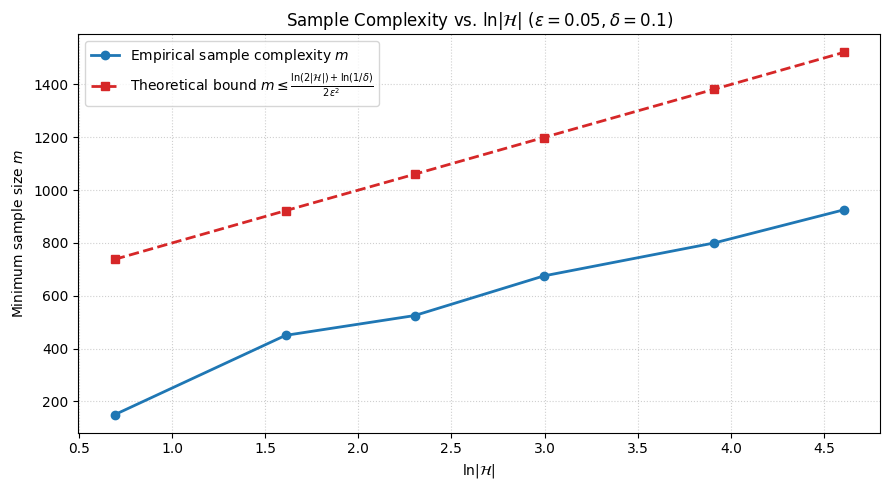

In [ ]:
delta=0.10
H_vals=[2,5,10,20,50,100]
m_search_grid=np.arange(50,1500,25)

empirical_m=[]

for k in H_vals:
  p_vec=np.linspace(0.1,0.9,k)
  found_m=m_search_grid[-1]
  for m in m_search_grid:
    errors_matrix=np.random.binomial(m,p_vec,size=(n_simulations,k))
    emp_risks_matrix=errors_matrix/m
    max_devs=np.max(np.abs(emp_risks_matrix-p_vec),axis=1)
    prob_fail=np.mean(max_devs>epsilon)
    if prob_fail<=delta:
      found_m=m
      break
  empirical_m.append(found_m)

H_vals_arr=np.array(H_vals)
theoretical_m=np.ceil((np.log(2*H_vals_arr)+np.log(1.0/delta))/(2.0*(epsilon**2)))

plt.figure(figsize=(9,5))
plt.plot(np.log(H_vals_arr),empirical_m,marker='o',color='tab:blue',linewidth=2,label='Empirical sample complexity $m$')
plt.plot(np.log(H_vals_arr),theoretical_m,marker='s',linestyle='--',color='tab:red',linewidth=2,label='Theoretical bound $m\\geq\\frac{\\ln(2|\\mathcal{H}|)+\\ln(1/\\delta)}{2\\epsilon^2}$')
plt.title(f'Sample Complexity vs. $\\ln|\\mathcal{{H}}|$ ($\\epsilon={epsilon},\\delta={delta}$)')
plt.xlabel('$\\ln|\\mathcal{H}|$')
plt.ylabel('Minimum sample size $m$')
plt.grid(True,linestyle=':',alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

### Part I - Uniform Convergence & Finite Hypothesis Classes - **ANALYSIS**

#### **Justification of Hyperparameters & Experimental Settings**

To ensure statistically sound results while maintaining computational efficiency, the following parameters were chosen across the experiments:
- **Number of Simulations ($n_{\text{simulations}}=5000$ in Part I / $1000$ in Parts II & III):** A large repetition count is necessary to smooth out empirical fluctuations, ensuring that the estimated probabilities $\mathbb{P}(\dots)$ reliably approximate true theoretical expectations (Law of Large Numbers).
- **Tolerance Threshold ($\epsilon=0.05$):** This represents a standard precision level for statistical machine learning bounds, defining a tight boundary for acceptable risk deviation.
- **Sample Sizes ($m$ ranges):** Spanning from small values ($m=10$) to large values ($m=1000$) captures both the high-variance regime where sample noise dominates and the asymptotic regime where uniform convergence holds.
- **Hypothesis Class Sizes ($|\mathcal{H}|$ up to $1000$):** Ranging from binary classes ($|\mathcal{H}|=2$) to large sets illustrates the logarithmic impact $\ln|\mathcal{H}|$ predicted by PAC learning theory.

#### **Empirical Risk as a Random Variable (Task 1)**

For an individual hypothesis $h_j$ with true risk $L_D(h_j)=p$, the number of empirical misclassifications over an i.i.d. training sample of size $m$ is distributed as a Binomial random variable $E_j\sim\mathcal{B}(m,p)$. Consequently, the empirical risk $L_S(h_j)=E_j/m$ satisfies:
$$\mathbb{E}[L_S(h_j)]=p,\quad\operatorname{Var}(L_S(h_j))=\frac{p(1-p)}{m}$$
As observed empirically across $m\in\{10,50,200,1000\}$, the empirical distributions remain centered at $p=0.3$ while their variance vanishes asymptotically at rate $\mathcal{O}(1/m)$, illustrating the Law of Large Numbers.

#### **Individual Hoeffding Bound (Task 2)**

The empirical deviation probability $\mathbb{P}(|L_S(h_j)-L_D(h_j)|>\epsilon)$ decays exponentially with $m$, strictly upper-bounded by the Hoeffding bound $2e^{-2m\epsilon^2}$. While individual risk estimation is guaranteed for any single hypothesis, this single-hypothesis guarantee does not suffice for learning because an Empirical Risk Minimizer (ERM) selects the best hypothesis *after* inspecting the sample $S$.

#### **The Union Bound & Finite Classes (Tasks 3, 4 & 5)**

When searching over a hypothesis space $\mathcal{H}=\{h_1,\dots,h_k\}$, uniform convergence requires controlling the maximum deviation over all hypotheses simultaneously:
$$\mathbb{P}\left(\max_{h\in\mathcal{H}}|L_S(h)-L_D(h)|>\epsilon\right)\le2|\mathcal{H}|e^{-2m\epsilon^2}$$

#### **Key empirical observations:**

- **Conservatism of the Union Bound**: The theoretical curve strictly bounds the empirical failure rate, but becomes conservative when hypothesis risks are correlated.
- **Logarithmic Dependence on $|\mathcal{H}|$**: The maximum deviation $\mathbb{E}[\max_h|L_S(h)-L_D(h)|]$ and the sample complexity scale proportionally to $\ln|\mathcal{H}|$. This slow logarithmic rate shows that finite hypothesis spaces remain learnable even when $|\mathcal{H}|$ grows large, provided $m=\Omega\left(\frac{\ln|\mathcal{H}|+\ln(1/\delta)}{\epsilon^2}\right)$.

# Part II - Simulating No-Free-Lunch

### Task 6 - Seen and Unseen Inputs

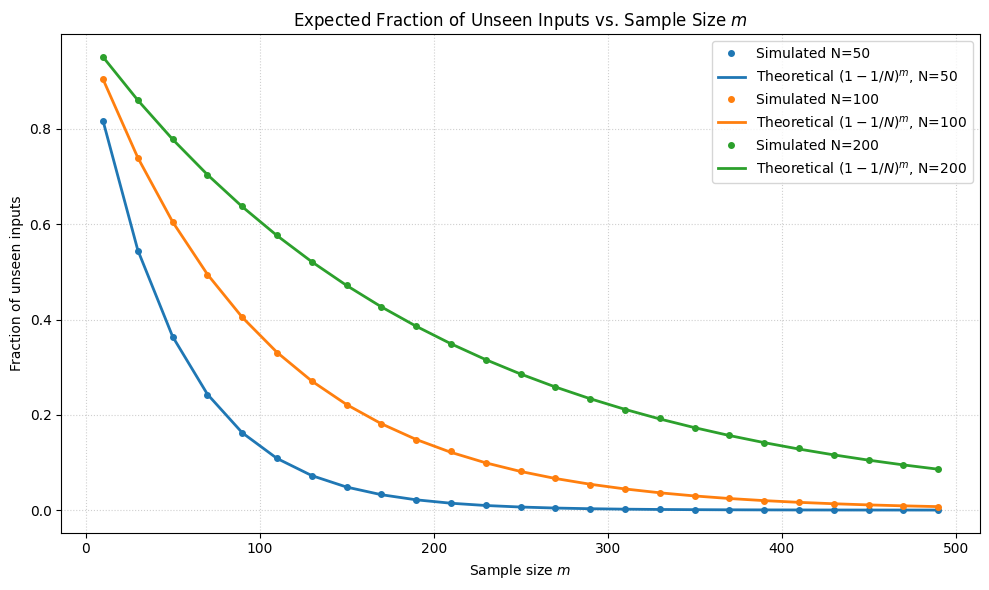

In [ ]:
N_values=[50,100,200]
m_values_task6=np.arange(10,501,20)
n_repetitions=1000

plt.figure(figsize=(10,6))
colors=['tab:blue','tab:orange','tab:green']

for idx,N in enumerate(N_values):
  simulated_unseen_fractions=[]
  for m in m_values_task6:
    samples=np.random.randint(0,N,size=(n_repetitions,m))
    unique_counts=np.array([len(np.unique(row))for row in samples])
    unseen_fractions=1.0-(unique_counts/N)
    simulated_unseen_fractions.append(np.mean(unseen_fractions))
  theoretical_unseen=(1.0-1.0/N)**m_values_task6
  plt.plot(m_values_task6,simulated_unseen_fractions,marker='o',markersize=4,linestyle='none',color=colors[idx],label=f'Simulated N={N}')
  plt.plot(m_values_task6,theoretical_unseen,linestyle='-',color=colors[idx],linewidth=2,label=f'Theoretical $(1-1/N)^m$, N={N}')

plt.title('Expected Fraction of Unseen Inputs vs. Sample Size $m$')
plt.xlabel('Sample size $m$')
plt.ylabel('Fraction of unseen inputs')
plt.grid(True,linestyle=':',alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

### Task 7 - Error on Unseen Inputs

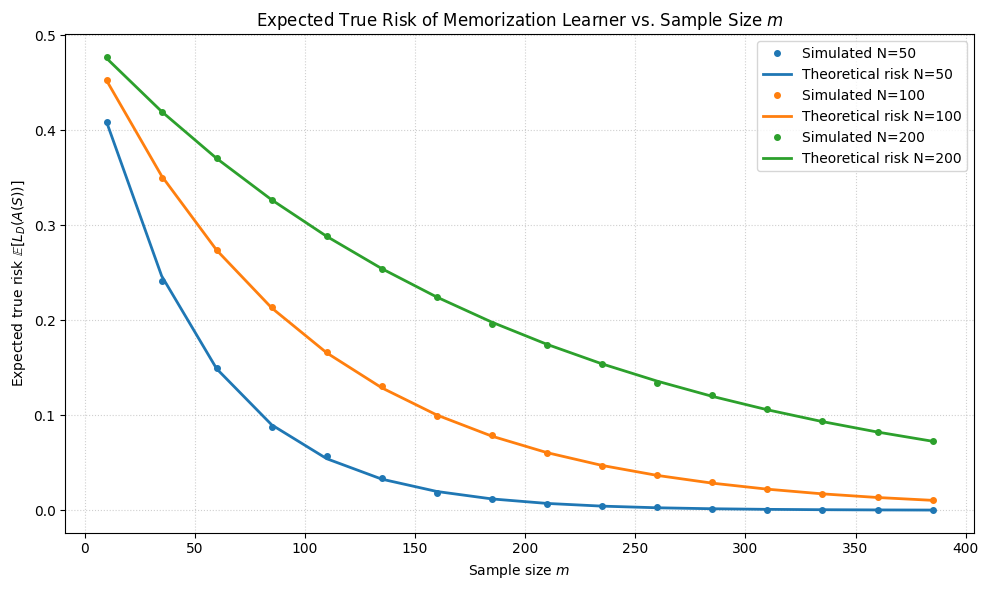

In [ ]:
N_values_task7=[50,100,200]
m_values_task7=np.arange(10,401,25)
n_rep_task7=500

plt.figure(figsize=(10,6))
colors=['tab:blue','tab:orange','tab:green']

for idx,N in enumerate(N_values_task7):
  simulated_risks=[]
  for m in m_values_task7:
    rep_errors=[]
    for _ in range(n_rep_task7):
      f_target=np.random.randint(0,2,size=N)
      sample=np.random.randint(0,N,size=m)
      seen_mask=np.zeros(N,dtype=bool)
      seen_mask[sample]=True
      error_count=np.sum(f_target[~seen_mask]!=0)
      rep_errors.append(error_count/N)
    simulated_risks.append(np.mean(rep_errors))
  theoretical_risks=0.5*((1.0-1.0/N)**m_values_task7)
  plt.plot(m_values_task7,simulated_risks,marker='o',markersize=4,linestyle='none',color=colors[idx],label=f'Simulated N={N}')
  plt.plot(m_values_task7,theoretical_risks,linestyle='-',color=colors[idx],linewidth=2,label=f'Theoretical risk N={N}')

plt.title('Expected True Risk of Memorization Learner vs. Sample Size $m$')
plt.xlabel('Sample size $m$')
plt.ylabel('Expected true risk $\\mathbb{E}[L_D(A(S))]$')
plt.grid(True,linestyle=':',alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

### Task 8 - Changing the Prediction on Unseen Inputs

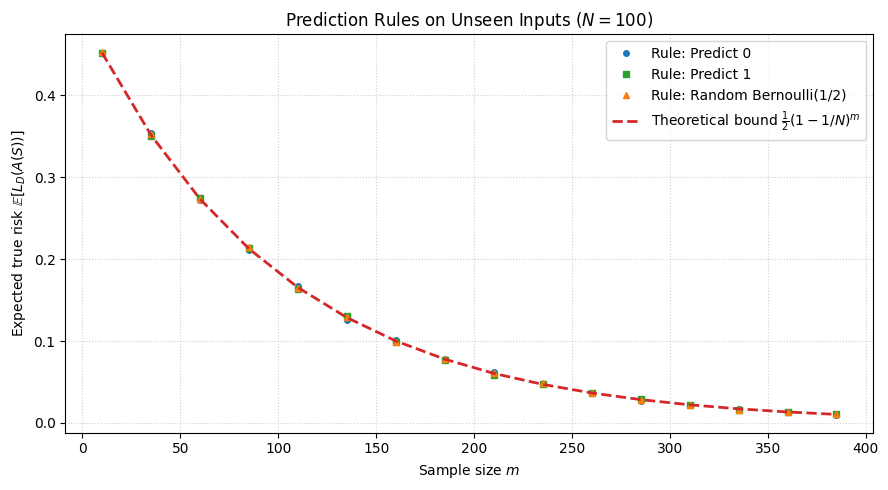

In [ ]:
N_task8=100
m_values_task8=np.arange(10,401,25)
n_rep_task8=500

risks_rule_0=[]
risks_rule_1=[]
risks_rule_rand=[]

for m in m_values_task8:
  err_0=[]
  err_1=[]
  err_rand=[]
  for _ in range(n_rep_task8):
    f_target=np.random.randint(0,2,size=N_task8)
    sample=np.random.randint(0,N_task8,size=m)
    seen_mask=np.zeros(N_task8,dtype=bool)
    seen_mask[sample]=True
    unseen_indices=np.where(~seen_mask)[0]
    n_unseen=len(unseen_indices)
    if n_unseen>0:
      err_0.append(np.sum(f_target[unseen_indices]!=0)/N_task8)
      err_1.append(np.sum(f_target[unseen_indices]!=1)/N_task8)
      rand_preds=np.random.randint(0,2,size=n_unseen)
      err_rand.append(np.sum(f_target[unseen_indices]!=rand_preds)/N_task8)
    else:
      err_0.append(0.0)
      err_1.append(0.0)
      err_rand.append(0.0)
  risks_rule_0.append(np.mean(err_0))
  risks_rule_1.append(np.mean(err_1))
  risks_rule_rand.append(np.mean(err_rand))

theoretical_task8=0.5*((1.0-1.0/N_task8)**m_values_task8)

plt.figure(figsize=(9,5))
plt.plot(m_values_task8,risks_rule_0,marker='o',markersize=4,linestyle='none',color='tab:blue',label='Rule: Predict 0')
plt.plot(m_values_task8,risks_rule_1,marker='s',markersize=4,linestyle='none',color='tab:green',label='Rule: Predict 1')
plt.plot(m_values_task8,risks_rule_rand,marker='^',markersize=4,linestyle='none',color='tab:orange',label='Rule: Random Bernoulli(1/2)')
plt.plot(m_values_task8,theoretical_task8,linestyle='--',color='tab:red',linewidth=2,label=r'Theoretical bound $\frac{1}{2}(1-1/N)^m$')
plt.title(f'Prediction Rules on Unseen Inputs ($N={N_task8}$)')
plt.xlabel('Sample size $m$')
plt.ylabel(r'Expected true risk $\mathbb{E}[L_D(A(S))]$')
plt.grid(True,linestyle=':',alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

### Part II - The No-Free-Lunch Theorem & Learning Without Inductive Bias - **ANALYSIS**

#### **Seen and Unseen Domain Points (Task 6)**

Under uniform distribution over $\mathcal{X}=\{1,\dots,N\}$, drawing $m$ i.i.d. samples with replacement leaves an element $x\in\mathcal{X}$ unobserved with probability $(1-1/N)^m$. By linearity of expectation, the expected fraction of unseen instances across the entire domain matches:
$$\mathbb{E}\left[\frac{|\mathcal{X}\setminus S|}{N}\right]=\left(1-\frac{1}{N}\right)^m$$
The empirical simulation matches this closed-form curve across all sample sizes.

#### **Generalization Failure on Random Targets (Task 7)**

When the target function $f:\mathcal{X}\to\{0,1\}$ is generated uniformly at random with $f(x)\sim\text{Bernoulli}(1/2)$, the training sample $S$ provides zero statistical information regarding the labels of unobserved points $\mathcal{X}\setminus S$. For a pure memorization learner predicting $0$ on unseen inputs:
- Empirical training error is identically zero: $L_S(A(S))=0$.
- True generalization risk satisfies:
$$\mathbb{E}[L_D(A(S))]=\frac{1}{N}\sum_{x\in\mathcal{X}}\mathbb{P}(x\notin S)\cdot\mathbb{P}(f(x)\ne0)=\frac{1}{2}\left(1-\frac{1}{N}\right)^m$$
When $m\ll N$, this expected error remains close to $0.5$ (equivalent to random guessing), despite achieving perfect training accuracy.

#### **Invariance to Unseen Prediction Rules (Task 8)**

Replacing the unseen prediction rule (predicting $0$, predicting $1$, or flipping a fair coin) produces identical expected true risk curves. Because the labels on unseen points are independent fair Bernoulli trials, every deterministic or randomized mapping exhibits an expected conditional error rate of $1/2$. No learning algorithm can outperform any other average across all possible labeling functions.

# Part III - Introducing Prior Knowledge

### Tasks 9 & 10 - Introducing Prior Knowledge & Matching Inductive Bias

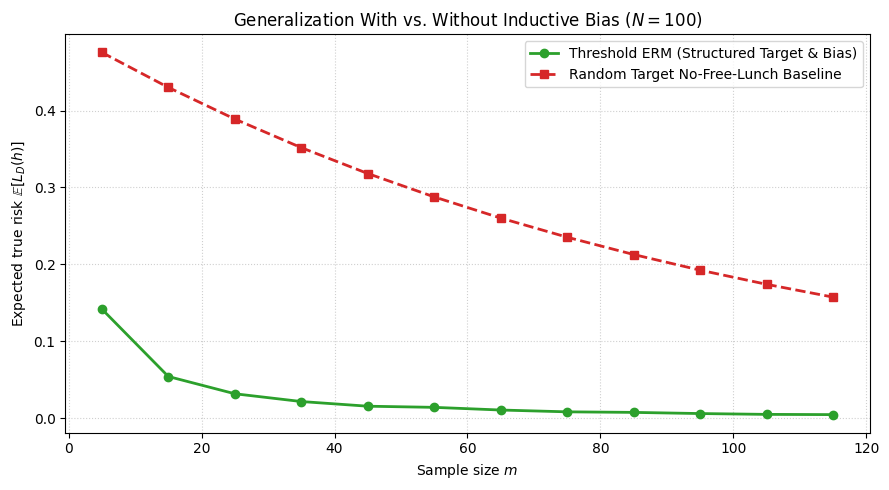

In [ ]:
N_task9=100
m_values_task9=np.arange(5,125,10)
n_rep_task9=1000
all_x=np.arange(1,N_task9+1)
candidate_thresholds=np.arange(1,N_task9)

erm_risks=[]
nfl_risks=[]

for m in m_values_task9:
  rep_erm_errors=[]
  rep_nfl_errors=[]
  for _ in range(n_rep_task9):
    theta=np.random.randint(1,N_task9)
    y_true=(all_x>theta).astype(int)
    sample_indices=np.random.randint(0,N_task9,size=m)
    s_x=all_x[sample_indices]
    s_y=(s_x>theta).astype(int)
    preds_all_t=(s_x[None,:]>candidate_thresholds[:,None]).astype(int)
    empirical_errors=np.mean(preds_all_t!=s_y[None,:],axis=1)
    best_t=candidate_thresholds[np.argmin(empirical_errors)]
    h_pred=(all_x>best_t).astype(int)
    rep_erm_errors.append(np.mean(h_pred!=y_true))
    rep_nfl_errors.append(0.5*((1.0-1.0/N_task9)**m))
  erm_risks.append(np.mean(rep_erm_errors))
  nfl_risks.append(np.mean(rep_nfl_errors))

plt.figure(figsize=(9,5))
plt.plot(m_values_task9,erm_risks,marker='o',color='tab:green',linewidth=2,label='Threshold ERM (Structured Target & Bias)')
plt.plot(m_values_task9,nfl_risks,marker='s',linestyle='--',color='tab:red',linewidth=2,label='Random Target No-Free-Lunch Baseline')
plt.title(f'Generalization With vs. Without Inductive Bias ($N={N_task9}$)')
plt.xlabel('Sample size $m$')
plt.ylabel(r'Expected true risk $\mathbb{E}[L_D(h)]$')
plt.grid(True,linestyle=':',alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

### Part III - Inductive Bias and Final Synthesis - **ANALYSIS & SYNTHESIS**

#### **The Power of Inductive Bias (Tasks 9 & 10)**

Restricting the learner to the hypothesis class of threshold classifiers $\mathcal{H}_{\text{thresh}}=\{x\mapsto\mathbb{1}[x>t]\}$ fundamentally transforms the learning problem:
- **Drastic Reduction in Capacity**: Instead of considering all $2^N$ arbitrary labelings, the learner restricts its search to $|\mathcal{H}_{\text{thresh}}|=N-1$ structured hypotheses.
- **Rapid Generalization**: As demonstrated in the comparison graph, the expected risk of the threshold ERM drops sharply towards zero with sample sizes $m\ll N$, whereas the unconstrained NFL baseline remains trapped near $0.5$.
- Even points never observed during training are accurately classified because the monotonic structure links observed labels to unseen regions.

#### **Comprehensive Synthesis (Task 11)**

- **The Core Trade-off**: Learning without assumptions (without inductive bias) is mathematically impossible, as established by the No-Free-Lunch theorem. A learning algorithm cannot generalize to unseen instances without prior assumptions regarding the data-generating distribution or target concept.
- **The Necessity of Hypothesis Spaces**: Imposing an inductive bias by restricting the search space to a constrained hypothesis class $\mathcal{H}$ enables uniform convergence. It guarantees that empirical risk minimization accurately reflects true generalization performance.
- **Capacity vs. Approximation**: If $\mathcal{H}$ is too expressive (e.g., all functions over $\mathcal{X}$), uniform convergence fails and sample complexity diverges. Conversely, when $\mathcal{H}$ is sufficiently restricted and matches the underlying problem structure, PAC learnability is achieved with sample complexity scaling logarithmically with $|\mathcal{H}|$.